# Implicit advection–diffusion verification

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §5.3.5, p. 48.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

Combine positive-velocity upwind advection and central diffusion into a spatial matrix A. Backward Euler solves (I-dt*A)c_new=c_old. Periodic boundaries are explicit in the cyclic stencil. Implicit stepping removes the explicit stability restriction for this problem, not the requirement to resolve physical changes accurately.

Use c(x,0)=sin(2*pi*x) on a unit periodic interval. Its exact evolution is exp(-D*(2*pi)²*t)*sin(2*pi*(x-v*t)). A manufactured or known solution is essential for checking signs, scaling and boundary indexing.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

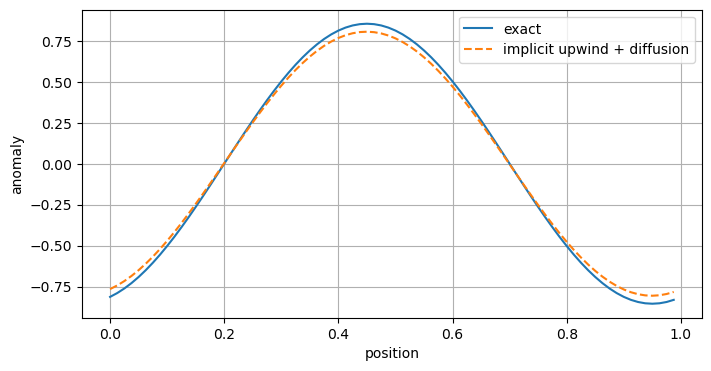

RMS errors: [np.float64(0.1254173139426274), np.float64(0.06693874624474705), np.float64(0.03457122124573309)]


In [2]:
errors=[]
for N in [20,40,80]:
 x=np.arange(N)/N;dx=1/N;v=1.;D=.02;T=.2;steps=N;dt=T/steps
 I=np.eye(N);back=(I-np.roll(I,1,axis=0))/dx
 lap=(np.roll(I,1,axis=0)-2*I+np.roll(I,-1,axis=0))/dx**2
 A=-v*back+D*lap;c=np.sin(2*np.pi*x)
 for _ in range(steps):c=np.linalg.solve(I-dt*A,c)
 exact=np.exp(-D*(2*np.pi)**2*T)*np.sin(2*np.pi*(x-v*T))
 errors.append(np.sqrt(np.mean((c-exact)**2)))
 if N==80:
  plt.plot(x,exact,label="exact");plt.plot(x,c,"--",label="implicit upwind + diffusion")
plt.xlabel("position");plt.ylabel("anomaly");plt.legend();plt.show()
print("RMS errors:",errors);assert np.all(np.diff(errors)<0)

## Read the result

Spatial upwind error is first order and can dominate central diffusion error. Refine time and space independently when identifying which error limits a simulation. Dense matrices here support teaching, not large-scale performance.

## Your turn

Hold dx fixed and reduce dt. Then hold dt sufficiently small and refine dx. Explain why the two studies answer different questions.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.